In [1]:
# Cell 1: 依赖库导入 / Importing Dependencies
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Mesa 核心组件导入 (适配 Mesa 3.x 及以上版本) / Importing Mesa Core Components (Compatible with Mesa 3.x and above)
import mesa
from mesa import Agent, Model
from mesa.space import SingleGrid
from mesa.datacollection import DataCollector

# 设置随机种子以保证实验可复现性（调试时可用，若要随机可设为 None） / Set random seed for reproducibility (useful for debugging, set to None for randomness)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("✅ Cell 1: 依赖库导入完成，Mesa 版本 / Dependencies imported successfully, Mesa version:", mesa.__version__)

✅ Cell 1: 依赖库导入完成，Mesa 版本 / Dependencies imported successfully, Mesa version: 3.3.1


In [2]:
# Cell 2: 全局超级参数配置中心 / Global Hyperparameter Configuration Center
# ==============================================================================
# 1. 空间与地图参数 / Environment & Spatial Config
# ==============================================================================
GRID_WIDTH = 100               # 网格宽度 (X轴) / Grid width (X-axis)
GRID_HEIGHT = 100              # 网格高度 (Y轴) / Grid height (Y-axis)
EAST_BOUNDARY_X = 50           # 东部高资源区划分线 (X >= 50 为东部) / Eastern high-resource zone boundary (X >= 50 is East)

RESOURCE_SPAWN_PROB = 0.08     # 每一轮全图每个空格子刷新资源的概率 / Resource spawn probability per empty cell per step
BASE_RESOURCE_VAL = 10         # 西部(左侧)空格子刷新的基础资源量 / Base resource amount in Western (left) empty cells
EAST_RESOURCE_MULTIPLIER = 1.5 # 东部(右侧)资源的倍率 n / Multiplier 'n' for Eastern (right) resources
TECH_BOOST_RATIO = 0.20        # 科学发现触发后，全局资源刷新上限的提升比例 (+20%) / Global resource spawn cap boost ratio after tech discovery (+20%)

# ==============================================================================
# 2. Population 规模与五类人格初始配置 (全属性冻结版) / Population Size & Initial Archetype Config (Frozen Stats Version)
# ==============================================================================
INIT_AGENTS_COUNT = 100        # 初始生成的 Agent 总数 / Total initial agent count

ARCHETYPE_RATIOS = {
    "Social_Darwinist": 0.15,   # 社会达尔文主义者 / Social Darwinist
    "Moral_Artist":     0.15,   # 道德表演艺术家 / Moral Artist
    "Ruffian":          0.15,   # 打手 / 暴徒 / Ruffian / Thug
    "Mob":              0.45,   # 庸众 / 暴民 / Mob / Commoner
    "Hermit_Sage":      0.10    # 隐士 / 智者 / Hermit / Sage
}

# 属性点分配基准 [Int, Inf, Mor, Imp_V, Exp_V, Exp_T] / Base Stat Allocation [Int, Inf, Mor, Imp_V, Exp_V, Exp_T]
# 【已冻结】：已去除 ±5 的浮动，Agent 生成时严格使用基准属性 / [FROZEN]: Removed ±5 fluctuation; agents strictly use base stats upon generation
ARCHETYPE_BASE_STATS = {
    "Social_Darwinist": {"int": 85, "inf": 80, "mor": 20, "imp_v": 90, "exp_v": 15, "exp_t": 40},
    "Moral_Artist":     {"int": 60, "inf": 90, "mor": 30, "imp_v": 20, "exp_v": 5,  "exp_t": 20},
    "Ruffian":          {"int": 30, "inf": 30, "mor": 10, "imp_v": 30, "exp_v": 90, "exp_t": 5},
    "Mob":              {"int": 40, "inf": 40, "mor": 50, "imp_v": 40, "exp_v": 40, "exp_t": 15},
    "Hermit_Sage":      {"int": 90, "inf": 20, "mor": 80, "imp_v": 5,  "exp_v": 5,  "exp_t": 90}
}
ARCHETYPE_STAT_JITTER = 0      # 属性随机浮动值为 0 (锁定静态基准) / Stat random jitter set to 0 (locks static baseline)

# ==============================================================================
# 3. 生存、生命周期与繁殖遗传参数 / Survival, Life Cycle, Reproduction & Buffs
# ==============================================================================
INIT_RESOURCE_PER_AGENT = 100  # 初始资源量 / Initial resource amount
BASE_CONSUMPTION = 2           # 基础生存消耗 / Base survival consumption
MOVE_STEP_LIMIT = 5            # 最长移动距离 / Max movement distance per step

STARVE_LIMIT_STEPS = 10        # 饥饿死亡阈值 / Starvation death threshold (steps)
RETIRE_AGE_STEPS = 6000        # 衰老起点 / Aging onset threshold (steps)
OLD_AGE_DEATH_PROB = 0.01      # 衰老死亡递增概率 / Old age death probability step

# 遗传概率公式参数: P(Type) = HEREDITY_BASE_PROB + is_parent_1*0.05 + is_parent_2*0.05 / Heredity formula params
HEREDITY_BASE_PROB = 0.18      # 非父母类型的基准继承概率 (18%) / Base inheritance probability for non-parent archetype (18%)
HEREDITY_PARENT_BONUS = 0.05   # 父母类型单方贡献的额外加成 (5%) / Additional bonus contributed per parent archetype match (5%)

# 关系暂态属性加成 (关系成立时挂载，解绑即还原) / Transient relationship stat buffs (applied when active, reverted on unbind)
BUFF_MARRIAGE = {"int": 10, "inf": 10, "mor": 10, "imp_v": 0,  "exp_v": 5,  "exp_t": 5}
BUFF_SOCIETY  = {"int": 15, "inf": 15, "mor": 15, "imp_v": 10, "exp_v": 10, "exp_t": 10}

# ==============================================================================
# 4. 机制与科研参数 / Phase 1/2 Mechanics & IQ-Driven Research
# ==============================================================================
WEIGHT_INT_RATIO = 0.6         # 竞拍中智力权重 / Intelligence weight in auction
WEIGHT_INF_RATIO = 0.4         # 竞拍中影响力权重 / Influence weight in auction

STEAL_BASE_RATIO = 0.3         # 基础掠夺比例 / Base plunder ratio
EXPLICIT_VIOLENCE_CRIT_MULT = 2.0 # 暴击系数 / Critical strike multiplier
PUNISH_PROB_EXPLICIT = 0.30    # 反抗/惩罚概率 / Resistance/Punishment probability
PUNISH_PENALTY_RATIO = 0.50    # 惩罚扣除比例 / Punishment deduction ratio

# IQ 驱动的科研参数 / IQ-driven Research Parameters
TECH_PROGRESS_THRESHOLD = 500  # 全局科研阈值 / Global research progress threshold
TECH_BASE_SUCCESS_PROB = 0.05  # 基础科研成功率 / Base research success probability
TECH_INT_PROB_COEFF = 0.005    # 智力对成功率加成系数: Success_P = Base + IQ * Coeff / Intelligence bonus coefficient for success probability
TECH_BASE_CONTRIBUTION = 10    # 基础进度贡献值 / Base progress contribution
TECH_INT_CONTRIB_MULT = 0.02   # 智力对进度贡献的放大系数: Contrib = Base * (1 + IQ * Mult) / Intelligence multiplier for progress contribution

# ==============================================================================
# 5. 结社与社会关系参数 / Society System - Replacing Alliance/Follower
# ==============================================================================
MARRY_RESOURCE_MIN = 150       # 结婚门槛 / Marriage resource threshold
BREED_RESOURCE_MIN = 300       # 繁殖门槛 / Breeding resource threshold
BREED_COST_RATIO = 0.30        # 抚养费比例 / Childcare cost ratio
DIVORCE_COOLDOWN_STEPS = 50    # 离婚冷却期 / Divorce cooldown steps

# 结社 (Society) 核心规则 / Society System Core Rules
SOCIETY_MORAL_DIFF_MAX = 20    # 允许发起/加入结社的最大道德差值 / Max moral difference allowed to initiate or join a society
SOCIETY_DOUBLE_RESOURCE_PROB = 0.20 # 采集中触发资源翻倍的几率 (20%) / Chance to trigger double resource yield during gathering (20%)
SOCIETY_EXIT_PENALTY_RATIO = 0.50   # 主动退社惩罚：强行扣除当前资源 50% / Penalty for voluntarily leaving society: 50% resource deduction
SOCIETY_RESCUE_THRESHOLD = 10  # 资助门槛：当社员资源 <= 10 时触发结社防饿死救济 / Relief threshold: triggers society starvation relief when member resources <= 10

print("✅ Cell 2: 全局超级参数配置中心更新成功！所有新增机制变量已就位。 / Global Hyperparameter Configuration Center updated successfully! All new feature variables are in place.")

✅ Cell 2: 全局超级参数配置中心更新成功！所有新增机制变量已就位。 / Global Hyperparameter Configuration Center updated successfully! All new feature variables are in place.


In [3]:
# Cell 3: 社交网络与结社管理数据结构 / Social Network & Society Management Data Structure
# ==============================================================================

class SocialNetwork:
    """
    维护 Agent 之间的社交图谱，处理信息共享、信任度、婚姻及结社拓扑。
    关系类型包括: 'marriage' (婚姻), 'society' (结社), 'kinship' (亲属)
    
    Maintains the social graph among agents, handling information sharing, trust, marriage, and society topology.
    Relationship types include: 'marriage', 'society', 'kinship'.
    """
    def __init__(self):
        self.graph = nx.Graph()

    def add_agent(self, agent_id, society_id=None):
        """将 Agent 注册到社交网络并记录其结社 ID / Register an Agent into the social network and record its society ID"""
        if not self.graph.has_node(agent_id):
            self.graph.add_node(agent_id, society_id=society_id)

    def remove_agent(self, agent_id):
        """Agent 死亡时从网络中注销 / Unregister Agent from the network upon death"""
        if self.graph.has_node(agent_id):
            self.graph.remove_node(agent_id)

    def add_relation(self, agent_a_id, agent_b_id, relation_type):
        """添加或更新双向关系边 / Add or update bidirectional relationship edge"""
        self.add_agent(agent_a_id)
        self.add_agent(agent_b_id)
        self.graph.add_edge(agent_a_id, agent_b_id, type=relation_type)

    def remove_relation(self, agent_a_id, agent_b_id, relation_type=None):
        """移除指定类型的关系边 / Remove specified type of relationship edge"""
        if self.graph.has_edge(agent_a_id, agent_b_id):
            if relation_type is None or self.graph[agent_a_id][agent_b_id].get('type') == relation_type:
                self.graph.remove_edge(agent_a_id, agent_b_id)

    # --------------------------------------------------------------------------
    # 结社 (Society) 核心逻辑：单一结社约束、成员检索与退出惩罚
    # Society Core Logic: Single society constraint, member retrieval & exit penalty
    # --------------------------------------------------------------------------
    def get_society_id(self, agent_id):
        """获取 Agent 当前所属的结社 ID（若未加入则返回 None） / Get current society ID of the Agent (returns None if not joined)"""
        if self.graph.has_node(agent_id):
            return self.graph.nodes[agent_id].get('society_id', None)
        return None

    def set_society_id(self, agent_id, society_id):
        """绑定 Agent 的结社（确保单一结社限制） / Bind Agent's society (enforcing single society constraint)"""
        self.add_agent(agent_id)
        self.graph.nodes[agent_id]['society_id'] = society_id

    def get_society_members(self, society_id, model=None):
        """获取同一个结社内的所有成员 ID 或 Agent 对象 / Get all member IDs or Agent objects within the same society"""
        if society_id is None:
            return []
        member_ids = [
            node for node, attr in self.graph.nodes(data=True) 
            if attr.get('society_id') == society_id
        ]
        if model and hasattr(model, 'agents_dict'):
            return [model.agents_dict[m_id] for m_id in member_ids if m_id in model.agents_dict]
        return member_ids

    def leave_society(self, agent):
        """
        退出结社处理：
        1. 扣除 50% 资源作为惩罚
        2. 清除网络中的结社边与成员关系
        3. 清除 Agent 自身的 Buff 与结社标记
        
        Process leaving society:
        1. Deduct 50% resources as a penalty
        2. Clear society edges and member relationships in network
        3. Clear Agent's own Buffs and society tags
        """
        current_society_id = self.get_society_id(agent.unique_id)
        if current_society_id is None:
            return False

        # 1. 执行退社惩罚 (扣除 50% 资源) / 1. Execute exit penalty (deduct 50% resources)
        penalty = agent.resources * SOCIETY_EXIT_PENALTY_RATIO
        agent.resources -= penalty

        # 2. 从拓扑图解绑所有社员的关系边 / 2. Unbind relationship edges of all society members from the topology graph
        members = self.get_society_members(current_society_id)
        for m_id in members:
            if m_id != agent.unique_id:
                self.remove_relation(agent.unique_id, m_id, relation_type='society')

        # 3. 清理节点上的结社标记 / 3. Clear society tags on the node
        self.set_society_id(agent.unique_id, None)

        # 4. 移除暂态属性 Buff (调用 Agent 层的通用接口) / 4. Remove transient attribute Buff (call generic interface on Agent layer)
        if hasattr(agent, 'remove_buff'):
            agent.remove_buff('society')

        return True

    # --------------------------------------------------------------------------
    # 信息广播与强社交圈检索 / Information Broadcasting & Strong Social Circle Retrieval
    # --------------------------------------------------------------------------
    def get_relatives_and_society_members(self, agent_id):
        """获取强社交圈（配偶、社员、直系亲属），用于互助与广播 / Retrieve strong social circle (spouses, society members, immediate kin) for mutual aid and broadcasting"""
        if not self.graph.has_node(agent_id):
            return []
        
        close_ids = set()
        # 获取婚姻与亲属节点 / Get marriage and kinship nodes
        for neighbor in self.graph.neighbors(agent_id):
            edge_type = self.graph[agent_id][neighbor].get('type')
            if edge_type in ['marriage', 'kinship']:
                close_ids.add(neighbor)

        # 获取结社同伴 / Get society companions
        soc_id = self.get_society_id(agent_id)
        if soc_id is not None:
            for m_id in self.get_society_members(soc_id):
                if m_id != agent_id:
                    close_ids.add(m_id)

        return list(close_ids)

    def broadcast_resource_info(self, source_agent, target_pos, model):
        """高浓度资源点信息在配偶、社员与亲属间广播 / Broadcast high-density resource location info among spouses, society members, and kin"""
        close_ids = self.get_relatives_and_society_members(source_agent.unique_id)
        for target_id in close_ids:
            if target_id in model.agents_dict:
                ally = model.agents_dict[target_id]
                if ally.known_high_resource_pos is None:
                    ally.known_high_resource_pos = target_pos

print("✅ Cell 3: 社交网络与结社管理模块重构成功！ / Social network and society management module restructured successfully!")

✅ Cell 3: 社交网络与结社管理模块重构成功！ / Social network and society management module restructured successfully!


In [4]:
# Cell 4: Agent 核心类定义 (SocialAgent) - 结社与暂态Buff重构版 / Agent Core Class Definition (SocialAgent) - Restructured Society & Transient Buff Version
# ==============================================================================
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="mesa") # 屏蔽 Mesa 内部提示 / Suppress Mesa internal warnings

class SocialAgent(Agent):
    """
    具备 6 维属性向量、暂态关系 Buff 机制以及 IQ 驱动科研能力的智能体
    
    An agent with a 6-dimensional attribute vector, transient relationship Buff mechanisms, and IQ-driven research capabilities.
    """
    def __init__(self, model, archetype, pos=None):
        super().__init__(model)
        self.archetype = archetype  # 人格类型名 / Archetype name
        
        # ----------------------------------------------------------------------
        # 1. 资源与生命周期初始化 / Resource & Life Cycle Initialization
        # ----------------------------------------------------------------------
        self.resources = INIT_RESOURCE_PER_AGENT
        self.age = 0                # 年龄（轮数） / Age (steps)
        self.starve_steps = 0       # 连续饥饿轮数 / Consecutive starvation steps
        self.is_alive = True
        
        # ----------------------------------------------------------------------
        # 2. 6 维核心静态属性向量 (锁定版本：取消 ±5 随机浮动，严格使用基准)
        #    6-Dimensional Core Static Attribute Vector (Locked: Removed ±5 random jitter, strictly uses baseline)
        # ----------------------------------------------------------------------
        base_stats = ARCHETYPE_BASE_STATS[archetype]
        self.int = base_stats["int"]      # 智力 (Intelligence)
        self.inf = base_stats["inf"]      # 影响力 (Influence)
        self.mor = base_stats["mor"]      # 道德 (Morality)
        self.imp_v = base_stats["imp_v"]  # 隐性暴力 (Implicit Violence)
        self.exp_v = base_stats["exp_v"]  # 显性暴力 (Explicit Violence)
        self.exp_t = base_stats["exp_t"]  # 探索欲 (Exploration Tendency)

        # ----------------------------------------------------------------------
        # 3. 社交关系标记（移除旧联盟与追随者，统一合并为结社 Society）
        #    Social Relationship Tags (Removed legacy alliance/follower, unified under Society)
        # ----------------------------------------------------------------------
        self.spouse_id = None            # 配偶 unique_id / Spouse unique_id
        self.divorce_cooldown = 0        # 离婚冷却期 / Divorce cooldown steps
        self.society_id = None           # 所属结社 ID (单一结社限制) / Belonging society ID (single society constraint)
        self.children = []               # 子女 unique_id 列表 / Children unique_id list
        self.parents = []                # 父母 unique_id 列表 / Parents unique_id list
        
        # ----------------------------------------------------------------------
        # 4. 导航记忆与暂态 Buff 字典 / Navigation Memory & Transient Buff Dictionary
        # ----------------------------------------------------------------------
        self.known_high_resource_pos = None  # 共享获取的高资源格坐标 / Coordinates of known high-resource cell obtained via sharing
        self.active_buffs = {}              # 暂态属性 Buff 加成字典 / Transient attribute Buff bonus dictionary, e.g. {'marriage': BUFF_MARRIAGE, 'society': BUFF_SOCIETY}

    # --------------------------------------------------------------------------
    # 暂态 Buff 挂载与卸载逻辑 (解绑关系即自动失效)
    # Transient Buff Attachment & Detachment Logic (Automatically unbinds when relationship ends)
    # --------------------------------------------------------------------------
    def add_buff(self, buff_name, buff_dict):
        """挂载一个暂态属性 Buff (如结婚加成、结社加成) / Attach a transient attribute Buff (e.g., marriage bonus, society bonus)"""
        self.active_buffs[buff_name] = buff_dict

    def remove_buff(self, buff_name):
        """卸载指定暂态属性 Buff (解绑关系时调用) / Detach a specified transient attribute Buff (called upon relationship unbinding)"""
        if buff_name in self.active_buffs:
            del self.active_buffs[buff_name]

    # --------------------------------------------------------------------------
    # 动态属性计算 (effective_*): 基础属性 + 所有当前挂载 Buff 之和
    # Dynamic Attribute Calculation (effective_*): Base stat + sum of all currently active Buffs
    # --------------------------------------------------------------------------
    def _get_effective_stat(self, stat_name, base_value):
        bonus = sum(buff.get(stat_name, 0) for buff in self.active_buffs.values())
        return int(np.clip(base_value + bonus, 1, 100))

    @property
    def effective_int(self):
        return self._get_effective_stat("int", self.int)

    @property
    def effective_inf(self):
        return self._get_effective_stat("inf", self.inf)

    @property
    def effective_mor(self):
        return self._get_effective_stat("mor", self.mor)

    @property
    def effective_imp_v(self):
        return self._get_effective_stat("imp_v", self.imp_v)

    @property
    def effective_exp_v(self):
        return self._get_effective_stat("exp_v", self.exp_v)

    @property
    def effective_exp_t(self):
        return self._get_effective_stat("exp_t", self.exp_t)

    # --------------------------------------------------------------------------
    # IQ 驱动的科研概率与贡献计算 / IQ-Driven Research Probability & Contribution Calculation
    # --------------------------------------------------------------------------
    def get_research_success_prob(self):
        """科研成功率 = 基础概率 + 动态智商 * 智力加成系数 / Research Success Probability = Base Prob + Dynamic IQ * Intelligence Coeff"""
        prob = TECH_BASE_SUCCESS_PROB + self.effective_int * TECH_INT_PROB_COEFF
        return min(1.0, prob)

    def get_research_contribution(self):
        """智商越高的 Agent 成功科研时，对全局进度条贡献越大 / Agents with higher IQ contribute more to the global progress bar upon successful research"""
        contrib = TECH_BASE_CONTRIBUTION * (1.0 + self.effective_int * TECH_INT_CONTRIB_MULT)
        return contrib

    # --------------------------------------------------------------------------
    # 行为偏好与争夺权重计算 / Behavioral Preference & Competition Weight Calculation
    # --------------------------------------------------------------------------
    def get_explore_preference(self):
        """
        计算 Phase 2 选择【科研探索】还是【掠夺】的概率
        P(探索) = Effective_Exp_T / (Effective_Exp_T + 100 - Effective_Morality)
        
        Calculate probability of choosing [Research Exploration] vs [Predation] in Phase 2
        P(Explore) = Effective_Exp_T / (Effective_Exp_T + 100 - Effective_Morality)
        """
        explore_score = self.effective_exp_t
        predate_score = (100 - self.effective_mor) + 0.1  # 防止分母为 0 / Prevent division by zero
        p_explore = explore_score / (explore_score + predate_score)
        return p_explore

    def get_auction_weight(self):
        """Phase 1 局部 3x3 竞拍争夺权重: Dynamic_Int * 0.6 + Dynamic_Inf * 0.4 / Phase 1 local 3x3 auction competition weight: Dynamic_Int * 0.6 + Dynamic_Inf * 0.4"""
        return self.effective_int * WEIGHT_INT_RATIO + self.effective_inf * WEIGHT_INF_RATIO

    # --------------------------------------------------------------------------
    # 周期状态更新 / Lifecycle State Update
    # --------------------------------------------------------------------------
    def update_lifecycle(self):
        """每一轮更新年龄、消耗生存资源以及冷却状态 / Update age, consume survival resources, and update cooldown states each step"""
        self.age += 1
        self.resources -= BASE_CONSUMPTION
        
        # 扣减离婚冷却时间 / Deduct divorce cooldown steps
        if self.divorce_cooldown > 0:
            self.divorce_cooldown -= 1
            
        # 检查饥饿状态 / Check starvation status
        if self.resources <= 0:
            self.starve_steps += 1
        else:
            self.starve_steps = 0  # 恢复正常 / Reset to normal

print("✅ Cell 4: SocialAgent 核心类重构完成！ / SocialAgent core class restructured successfully!")

✅ Cell 4: SocialAgent 核心类重构完成！ / SocialAgent core class restructured successfully!


In [5]:
# Cell 5: Agent 三阶段动作逻辑实现 - 结社与暂态 Buff 整合版 / Agent Three-Phase Action Logic Implementation - Integrated Society & Transient Buff Version
# ==============================================================================

def agent_phase_1_move_and_collect(self):
    """Phase 1: 寻路移动与局部 3x3 资源竞拍 (支持结社采集翻倍) / Phase 1: Pathfinding Movement & Local 3x3 Resource Auction (Supports Society Yield Doubling)"""
    if not self.is_alive or self.pos is None:
        return

    # 1.1 寻路导航策略 (优先向共享导航点移动，否则向东部高资源区移动) / Pathfinding navigation strategy (Prioritize moving to shared waypoint, otherwise move to Eastern high-resource zone)
    target_pos = None
    if self.known_high_resource_pos:
        target_pos = self.known_high_resource_pos
    elif self.pos[0] < EAST_BOUNDARY_X:
        target_pos = (random.randint(EAST_BOUNDARY_X, GRID_WIDTH - 1), random.randint(0, GRID_HEIGHT - 1))

    # 在 MOVE_STEP_LIMIT 曼哈顿距离内选择最优移动位置 / Select optimal movement position within MOVE_STEP_LIMIT Manhattan distance
    possible_steps = self.model.grid.get_neighborhood(
        self.pos, moore=True, include_center=True, radius=MOVE_STEP_LIMIT
    )
    empty_steps = [p for p in possible_steps if self.model.grid.is_cell_empty(p) or p == self.pos]

    if empty_steps:
        if target_pos:
            best_step = min(empty_steps, key=lambda p: abs(p[0]-target_pos[0]) + abs(p[1]-target_pos[1]))
        else:
            best_step = random.choice(empty_steps)
        
        if best_step != self.pos:
            self.model.grid.move_agent(self, best_step)

    # 到达目的地后重置导航目标 / Reset navigation target upon arrival at destination
    if self.known_high_resource_pos and self.pos == self.known_high_resource_pos:
        self.known_high_resource_pos = None

    # 1.2 局部 3x3 资源竞拍收集 / 1.2 Local 3x3 resource auction collection
    neighbors_3x3 = self.model.grid.get_neighborhood(self.pos, moore=True, include_center=True, radius=1)
    for cell in neighbors_3x3:
        grid_res = self.model.grid_resources.get(cell, 0)
        
        if grid_res > 0:
            cell_agents = [a for a in self.model.grid.get_cell_list_contents(cell) if a.is_alive]
            if cell_agents:
                total_weight = sum(a.get_auction_weight() for a in cell_agents)
                if total_weight > 0:
                    my_share = grid_res * (self.get_auction_weight() / total_weight)
                    
                    # 结社特权：一定几率触发资源收集翻倍 / Society privilege: Chance to trigger doubled resource collection
                    if self.society_id is not None and random.random() < SOCIETY_DOUBLE_RESOURCE_PROB:
                        my_share *= 2.0
                        
                    self.resources += my_share
                    
                    # 清空/扣减该格资源（由最后一个处理的 agent 清空） / Clear/deduct cell resource (cleared by the last processed agent)
                    if self == cell_agents[-1]:
                        self.model.grid_resources[cell] = 0

            # 信息广播：只有格子里确实有高资源时才向强社交圈广播 / Information broadcasting: Broadcast to strong social circle only when high resources are present
            if grid_res >= BASE_RESOURCE_VAL * 2:
                self.model.social_net.broadcast_resource_info(self, cell, self.model)

def agent_phase_2_game_action(self):
    """Phase 2: 进阶动作（IQ 驱动科研 vs 限制掠夺） / Phase 2: Advanced Actions (IQ-Driven Research vs Restricted Predation)"""
    if not self.is_alive or self.pos is None:
        return

    p_explore = self.get_explore_preference()
    if random.random() < p_explore:
        # --- 选项 A: IQ 驱动科研探索 --- / --- Option A: IQ-Driven Research Exploration ---
        if random.random() < self.get_research_success_prob():
            tech_contrib = self.get_research_contribution()
            self.model.global_tech_progress += tech_contrib
    else:
        # --- 选项 B: 尝试掠夺 --- / --- Option B: Attempt Predation ---
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=1)
        # 排除条件：不掠夺自己、配偶、以及【同结社成员】 / Exclusion criteria: Do not rob self, spouse, or [same society members]
        potential_victims = [
            a for a in neighbors if a.is_alive 
            and a.unique_id != self.spouse_id 
            and (self.society_id is None or a.society_id != self.society_id)
        ]
        
        if potential_victims:
            # 挑选防御最弱者 (基于动态属性计算) / Target the weakest defender (calculated based on dynamic stats)
            victim = min(potential_victims, key=lambda a: a.effective_int)
            victim_def_stat = victim.effective_int

            my_attack = self.effective_int + self.effective_imp_v
            if my_attack > victim_def_stat:
                steal_ratio = STEAL_BASE_RATIO * (1.0 - self.effective_mor / 100.0)
                if random.random() < (self.effective_exp_v / 100.0):
                    steal_ratio *= EXPLICIT_VIOLENCE_CRIT_MULT
                
                stolen_amount = victim.resources * steal_ratio
                victim.resources -= stolen_amount
                self.resources += stolen_amount

            # 暴徒受法律/集体惩罚检测 / Check for legal/collective punishment against thugs
            if random.random() < (self.effective_exp_v / 100.0) * PUNISH_PROB_EXPLICIT:
                penalty = self.resources * PUNISH_PENALTY_RATIO
                self.resources -= penalty

def agent_phase_3_social_action(self):
    """Phase 3: 社会关系动作 (婚姻/离婚/结社发起与救济) / Phase 3: Social Relationship Actions (Marriage / Divorce / Society Formation & Relief)"""
    if not self.is_alive or self.pos is None:
        return

    # --------------------------------------------------------------------------
    # 3.1 离婚判定与拆分 / 3.1 Divorce Condition & Asset Splitting
    # --------------------------------------------------------------------------
    if self.spouse_id and self.spouse_id in self.model.agents_dict:
        spouse = self.model.agents_dict[self.spouse_id]
        if self.effective_mor < 30 and (self.resources < spouse.resources * 0.3):
            # 解除网络关系与 Buff / Unbind network relationship and Buffs
            self.model.social_net.remove_relation(self.unique_id, self.spouse_id, 'marriage')
            self.remove_buff('marriage')
            spouse.remove_buff('marriage')
            
            # 清除标记与冷却 / Clear tags and set cooldown
            spouse.spouse_id = None
            self.spouse_id = None
            self.divorce_cooldown = DIVORCE_COOLDOWN_STEPS
            spouse.divorce_cooldown = DIVORCE_COOLDOWN_STEPS
            
            # 财产平分 / Split resources equally
            total_res = self.resources + spouse.resources
            self.resources = total_res / 2.0
            spouse.resources = total_res / 2.0
            
            if "divorces" in self.model.step_events:
                self.model.step_events["divorces"] += 1

    # --------------------------------------------------------------------------
    # 3.2 结婚与繁殖判定 / 3.2 Marriage & Reproduction Conditions
    # --------------------------------------------------------------------------
    if not self.spouse_id and self.divorce_cooldown == 0 and self.resources >= MARRY_RESOURCE_MIN:
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=1)
        single_candidates = [
            a for a in neighbors if a.is_alive and not a.spouse_id 
            and a.divorce_cooldown == 0 and a.resources >= MARRY_RESOURCE_MIN
        ]
        if single_candidates:
            partner = random.choice(single_candidates)
            self.spouse_id = partner.unique_id
            partner.spouse_id = self.unique_id
            
            # 建立拓扑边并挂载双向暂态 Buff / Build topology edge and attach bidirectional transient Buffs
            self.model.social_net.add_relation(self.unique_id, partner.unique_id, 'marriage')
            self.add_buff('marriage', BUFF_MARRIAGE)
            partner.add_buff('marriage', BUFF_MARRIAGE)
            
            if "marriages" in self.model.step_events:
                self.model.step_events["marriages"] += 1

    # 繁殖判定 / Reproduction condition
    if self.spouse_id and self.spouse_id in self.model.agents_dict:
        spouse = self.model.agents_dict[self.spouse_id]
        if (self.resources + spouse.resources) >= BREED_RESOURCE_MIN:
            cost = (self.resources + spouse.resources) * BREED_COST_RATIO
            self.resources -= cost / 2.0
            spouse.resources -= cost / 2.0
            self.model.breed_child(self, spouse)

    # --------------------------------------------------------------------------
    # 3.3 结社 (Society) 发起、加入与成员互助救援
    #     3.3 Society Formation, Joining & Member Mutual Relief
    # --------------------------------------------------------------------------
    # A. 寻找并加入/发起结社 (单一结社限制) / A. Search and join/initiate society (single society constraint)
    if self.society_id is None:
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=2)
        # 筛选道德匹配的候选人 / Filter candidates with matching morality
        moral_matching_candidates = [
            a for a in neighbors if a.is_alive 
            and abs(self.effective_mor - a.effective_mor) <= SOCIETY_MORAL_DIFF_MAX
            and a.unique_id != self.unique_id
        ]
        
        if moral_matching_candidates:
            target = random.choice(moral_matching_candidates)
            
            if target.society_id is not None:
                # 1. 加入对方已有结社 / 1. Join target's existing society
                new_soc_id = target.society_id
                self.society_id = new_soc_id
                self.model.social_net.set_society_id(self.unique_id, new_soc_id)
                self.model.social_net.add_relation(self.unique_id, target.unique_id, 'society')
                self.add_buff('society', BUFF_SOCIETY)
            else:
                # 2. 双方均无结社，共同发起新结社 / 2. Neither has a society; jointly initiate a new society
                new_soc_id = f"soc_{self.unique_id}_{self.model.steps}"
                self.society_id = new_soc_id
                target.society_id = new_soc_id
                
                self.model.social_net.set_society_id(self.unique_id, new_soc_id)
                self.model.social_net.set_society_id(target.unique_id, new_soc_id)
                self.model.social_net.add_relation(self.unique_id, target.unique_id, 'society')
                
                self.add_buff('society', BUFF_SOCIETY)
                target.add_buff('society', BUFF_SOCIETY)

    # B. 结社内部饥饿救济（防饿死互助机制） / B. Internal society starvation relief (anti-starvation mutual aid)
    if self.society_id is not None and self.resources <= SOCIETY_RESCUE_THRESHOLD:
        soc_members = self.model.social_net.get_society_members(self.society_id, self.model)
        # 寻找有富余资源的社员 / Search for members with surplus resources
        helpers = [m for m in soc_members if m.unique_id != self.unique_id and m.resources > 50]
        for helper in helpers:
            rescue_amount = 5.0  # 富余社员每人划拨 5 点资源 / Each surplus member allocates 5 resource units
            if helper.resources > rescue_amount:
                helper.resources -= rescue_amount
                self.resources += rescue_amount

# 方法绑定挂载 / Method binding & mounting
SocialAgent.phase_1_move_and_collect = agent_phase_1_move_and_collect
SocialAgent.phase_2_game_action = agent_phase_2_game_action
SocialAgent.phase_3_social_action = agent_phase_3_social_action

print("✅ Cell 5: 动作逻辑重构完成！结社特权、科研与防饿死救援已全面生效。 / Action logic restructured successfully! Society privileges, research, and starvation relief are fully active.")

✅ Cell 5: 动作逻辑重构完成！结社特权、科研与防饿死救援已全面生效。 / Action logic restructured successfully! Society privileges, research, and starvation relief are fully active.


In [6]:
# Cell 6: 主模型类定义 (SocialModel) - 计算社会学全景数据诊断版 (数据打平优化版) / Main Model Class Definition (SocialModel) - Computational Sociology Panoramic Data Diagnostic Version (Data Flattening Optimized)
# ==============================================================================

class SocialModel(Model):
    """
    计算社会学主控模型: 负责环境刷新、科技演进、人口生死代谢与社会面貌诊断
    Computational Sociology Master Control Model: Responsible for environment refresh, tech evolution, population life cycle/metabolism, and social landscape diagnostics.
    """
    def __init__(self):
        super().__init__()
        self.grid = SingleGrid(GRID_WIDTH, GRID_HEIGHT, torus=False)
        self.social_net = SocialNetwork()
        
        # 基础状态索引 / Basic state indices
        self.agents_dict = {}
        self.grid_resources = {}          # (x, y) -> 资源量 / (x, y) -> Resource amount
        self.global_tech_progress = 0.0   # 全局科研进度 / Global research progress
        self.tech_boost_active = False    # 是否触发科技突破 Buff / Whether tech breakthrough Buff is triggered
        self.step_count = 0               # 运行轮数计数器 / Step run counter

        # ----------------------------------------------------------------------
        # 1. 单轮事件与全局累积事件追踪器 / 1. Single-step events and cumulative events tracker
        # ----------------------------------------------------------------------
        self.step_events = {
            "marriages": 0, "divorces": 0, "births": 0,
            "deaths_starve": 0, "deaths_age": 0
        }
        self.cum_events = {
            "births": 0, "deaths_starve": 0, "deaths_age": 0,
            "marriages": 0, "divorces": 0
        }

        # ----------------------------------------------------------------------
        # 2. 科学探索效能日志 (按人格分类) / 2. Scientific exploration efficiency log (Categorized by archetype)
        # ----------------------------------------------------------------------
        self.research_stats = {
            arch: {"valid": 0, "invalid": 0, "contrib": 0.0}
            for arch in ARCHETYPE_RATIOS.keys()
        }

        # ----------------------------------------------------------------------
        # 3. 初始化 Agent 并随机散布地图 / 3. Initialize Agents and randomly scatter across map
        # ----------------------------------------------------------------------
        archetypes = list(ARCHETYPE_RATIOS.keys())
        weights = list(ARCHETYPE_RATIOS.values())
        norm_weights = [w / sum(weights) for w in weights]

        all_positions = [(x, y) for x in range(GRID_WIDTH) for y in range(GRID_HEIGHT)]
        random.shuffle(all_positions)

        for i in range(min(INIT_AGENTS_COUNT, len(all_positions))):
            arch = np.random.choice(archetypes, p=norm_weights)
            pos = all_positions[i]
            
            agent = SocialAgent(self, arch, pos)
            self.grid.place_agent(agent, pos)
            self.agents_dict[agent.unique_id] = agent
            self.social_net.add_agent(agent.unique_id)

    def get_random_empty_pos(self):
        """网格空位安全查找工具函数 / Utility function for safely finding empty grid positions"""
        if hasattr(self.grid, 'empties') and self.grid.empties:
            return random.choice(list(self.grid.empties))
        
        empty_cells = [
            (x, y) for x in range(GRID_WIDTH) for y in range(GRID_HEIGHT) 
            if self.grid.is_cell_empty((x, y))
        ]
        return random.choice(empty_cells) if empty_cells else None

    def spawn_resources(self):
        """非对称地图资源刷新机制 / Asymmetric map resource spawning mechanism"""
        tech_multiplier = (1.0 + TECH_BOOST_RATIO) if self.tech_boost_active else 1.0
        
        for x in range(GRID_WIDTH):
            for y in range(GRID_HEIGHT):
                if self.grid.is_cell_empty((x, y)):
                    if random.random() < RESOURCE_SPAWN_PROB:
                        base_val = BASE_RESOURCE_VAL
                        if x >= EAST_BOUNDARY_X:
                            base_val *= EAST_RESOURCE_MULTIPLIER
                        
                        spawn_amount = base_val * tech_multiplier * random.uniform(0.8, 1.2)
                        self.grid_resources[(x, y)] = self.grid_resources.get((x, y), 0) + spawn_amount

    def log_research_attempt(self, agent, is_success, contrib_amount=0.0):
        """记录科研探索的有效/无效尝试与贡献 / Record valid/invalid attempts and contributions of scientific exploration"""
        arch = agent.archetype
        if is_success:
            self.research_stats[arch]["valid"] += 1
            self.research_stats[arch]["contrib"] += contrib_amount
            self.global_tech_progress += contrib_amount
        else:
            self.research_stats[arch]["invalid"] += 1

    def breed_child(self, parent1, parent2):
        """子代生成、人格类型遗传与亲属网络绑定 / Offspring generation, personality archetype inheritance, and kinship network binding"""
        empty_pos = self.get_random_empty_pos()
        if not empty_pos:
            return

        # --- 1. 计算子代成为各类人格的概率 / Calculate probability of offspring becoming each archetype ---
        archetypes = list(ARCHETYPE_RATIOS.keys())
        probs = []
        for arch in archetypes:
            p = 0.18  # 基础概率 18% / Base probability 18%
            if parent1.archetype == arch:
                p += 0.05  # 父母1 匹配 +5% / Parent 1 match +5%
            if parent2.archetype == arch:
                p += 0.05  # 父母2 匹配 +5% / Parent 2 match +5%
            probs.append(p)

        # 随机抽取子代的人格类型 / Randomly draw offspring's archetype
        child_arch = np.random.choice(archetypes, p=probs)
        
        # --- 2. 实例化子代 / Instantiate offspring ---
        child = SocialAgent(self, child_arch, empty_pos)

        # --- 3. 建立亲属关系链 / Establish kinship relationship chain ---
        parent1.children.append(child.unique_id)
        parent2.children.append(child.unique_id)
        child.parents = [parent1.unique_id, parent2.unique_id]
        self.social_net.add_relation(parent1.unique_id, child.unique_id, 'kinship')
        self.social_net.add_relation(parent2.unique_id, child.unique_id, 'kinship')

        self.grid.place_agent(child, empty_pos)
        self.agents_dict[child.unique_id] = child
        
        # 计数器更新 / Counter updates
        self.step_events["births"] += 1
        self.cum_events["births"] += 1

    def handle_death_and_inheritance(self, agent, cause="starve"):
        """注销死亡 Agent、解除婚姻关系与财产继承 / Unregister deceased Agent, dissolve marriage, and handle estate inheritance"""
        agent.is_alive = False
        self.grid.remove_agent(agent)
        
        if cause == "starve":
            self.step_events["deaths_starve"] += 1
            self.cum_events["deaths_starve"] += 1
        else:
            self.step_events["deaths_age"] += 1
            self.cum_events["deaths_age"] += 1

        # 解除配偶婚姻关系与 Buff / Dissolve spouse marriage relationship and Buffs
        if agent.spouse_id and agent.spouse_id in self.agents_dict:
            spouse = self.agents_dict[agent.spouse_id]
            spouse.spouse_id = None
            spouse.remove_buff('marriage')
            self.social_net.remove_relation(agent.unique_id, spouse.unique_id, 'marriage')

        # 遗产平分逻辑 (配偶与直系子女) / Estate equal distribution logic (Spouse and direct offspring)
        beneficiaries = []
        if agent.spouse_id and agent.spouse_id in self.agents_dict and self.agents_dict[agent.spouse_id].is_alive:
            beneficiaries.append(self.agents_dict[agent.spouse_id])
        for cid in agent.children:
            if cid in self.agents_dict and self.agents_dict[cid].is_alive:
                beneficiaries.append(self.agents_dict[cid])

        if beneficiaries and agent.resources > 0:
            share = agent.resources / len(beneficiaries)
            for b in beneficiaries:
                b.resources += share

        # 从网络与字典中剔除 / Remove from social network and agent dictionary
        self.social_net.remove_agent(agent.unique_id)
        del self.agents_dict[agent.unique_id]

    # --------------------------------------------------------------------------
    # 计算社会学全景数据采集核心函数 / Core Function for Collecting Panoramic Social Data
    # --------------------------------------------------------------------------
    def collect_social_metrics(self):
        """提取并计算全景社会诊断指标 (包含打平的 DataFrame 友好字段) / Extract and calculate panoramic social diagnostic metrics (including flattened DataFrame-friendly fields)"""
        active_agents = [a for a in self.agents_dict.values() if a.is_alive]
        total_pop = len(active_agents)
        if total_pop == 0:
            return {}

        # --- 1. 人口与财富基尼系数 / Population & Wealth Gini Coefficient ---
        resources = sorted([a.resources for a in active_agents])
        
        def calc_gini(array):
            array = np.asarray(array, dtype=np.float64)
            if array.size == 0 or np.sum(array) == 0:
                return 0.0
            array = np.sort(array)
            n = len(array)
            index = np.arange(1, n + 1)
            return float((np.sum((2 * index - n - 1) * array)) / (n * np.sum(array)))

        gini_wealth = calc_gini(resources)

        # --- 2. 人口结构与财富分布 / Demographic Structure & Wealth Distribution ---
        arch_pop = {k: 0 for k in ARCHETYPE_RATIOS.keys()}
        arch_wealth = {k: 0.0 for k in ARCHETYPE_RATIOS.keys()}
        total_wealth = sum(resources)

        for a in active_agents:
            arch_pop[a.archetype] += 1
            arch_wealth[a.archetype] += a.resources

        arch_pop_share = {k: v / total_pop for k, v in arch_pop.items()}
        arch_wealth_share = {k: (v / total_wealth if total_wealth > 0 else 0) for k, v in arch_wealth.items()}

        # --- 3. 婚姻状态全景矩阵与家庭规模 / Marital Status Panoramic Matrix & Family Size ---
        marital_status = {
            k: {"married": 0, "divorced": 0, "single": 0} 
            for k in ARCHETYPE_RATIOS.keys()
        }
        married_couples = 0
        
        for a in active_agents:
            arch = a.archetype
            if a.spouse_id is not None:
                marital_status[arch]["married"] += 1
                married_couples += 0.5  # 双向计数取半 / Halve for bidirectional counting
            elif a.divorce_cooldown > 0:
                marital_status[arch]["divorced"] += 1
            else:
                marital_status[arch]["single"] += 1

        marital_matrix = {}
        for k, v in arch_pop.items():
            if v > 0:
                marital_matrix[k] = {
                    "married_ratio": marital_status[k]["married"] / v,
                    "divorced_ratio": marital_status[k]["divorced"] / v,
                    "single_ratio": marital_status[k]["single"] / v,
                }
            else:
                marital_matrix[k] = {"married_ratio": 0.0, "divorced_ratio": 0.0, "single_ratio": 0.0}

        total_households = married_couples + (total_pop - married_couples * 2)
        avg_family_size = total_pop / total_households if total_households > 0 else 1.0

        # --- 4. 结社组织结构分析 / Society Organizational Structure Analysis ---
        societies = {}
        for a in active_agents:
            if a.society_id is not None:
                societies.setdefault(a.society_id, []).append(a)

        total_societies = len(societies)
        max_society_size = max([len(members) for members in societies.values()]) if societies else 0
        society_members_count = sum(len(m) for m in societies.values())
        
        society_member_arch_counts = {k: 0 for k in ARCHETYPE_RATIOS.keys()}
        society_leader_arch_counts = {k: 0 for k in ARCHETYPE_RATIOS.keys()}

        for soc_id, members in societies.items():
            for m in members:
                society_member_arch_counts[m.archetype] += 1
            leader = max(members, key=lambda x: x.effective_int)
            society_leader_arch_counts[leader.archetype] += 1

        society_member_share = {
            k: (v / society_members_count if society_members_count > 0 else 0)
            for k, v in society_member_arch_counts.items()
        }
        society_leader_share = {
            k: (v / total_societies if total_societies > 0 else 0)
            for k, v in society_leader_arch_counts.items()
        }

        # --- 5. 科学探索效能与人均贡献率 / Scientific Exploration Efficiency & Per Capita Contribution Rate ---
        research_metrics = {}
        total_valid = sum(s["valid"] for s in self.research_stats.values())
        total_invalid = sum(s["invalid"] for s in self.research_stats.values())
        total_attempts = total_valid + total_invalid
        
        overall_success_rate = (total_valid / total_attempts) if total_attempts > 0 else 0.0

        for k in ARCHETYPE_RATIOS.keys():
            v_cnt = self.research_stats[k]["valid"]
            inv_cnt = self.research_stats[k]["invalid"]
            tot = v_cnt + inv_cnt
            contrib = self.research_stats[k]["contrib"]
            pop_cnt = arch_pop[k]

            research_metrics[k] = {
                "valid": v_cnt,
                "invalid": inv_cnt,
                "success_rate": (v_cnt / tot) if tot > 0 else 0.0,
                "total_contrib": contrib,
                "per_capita_contrib": (contrib / pop_cnt) if pop_cnt > 0 else 0.0
            }

        # --- 6. 构建数据主字典 / Construct Primary Metrics Dictionary ---
        metrics = {
            "step": self.step_count,
            "total_pop": total_pop,
            "gini_wealth": gini_wealth,
            "arch_pop_share": arch_pop_share,
            "arch_wealth_share": arch_wealth_share,
            "avg_family_size": avg_family_size,
            "marital_matrix": marital_matrix,
            "total_societies": total_societies,
            "max_society_size": max_society_size,
            "society_member_share": society_member_share,
            "society_leader_share": society_leader_share,
            "global_tech_progress": self.global_tech_progress,
            "overall_research_success_rate": overall_success_rate,
            "research_metrics": research_metrics,
            "step_events": dict(self.step_events),
            "cum_events": dict(self.cum_events)
        }

        # --- 7. 打平（Flatten）展平列，确保转换 DataFrame 时可以直接提取 / Flatten columns to ensure direct extraction when converting to DataFrame ---
        for k in ARCHETYPE_RATIOS.keys():
            metrics[f"pop_share_{k}"] = arch_pop_share[k]
            metrics[f"wealth_share_{k}"] = arch_wealth_share[k]
            metrics[f"society_member_share_{k}"] = society_member_share[k]
            metrics[f"society_leader_share_{k}"] = society_leader_share[k]
            metrics[f"married_ratio_{k}"] = marital_matrix[k]["married_ratio"]
            
            # 核心科研打平字段 (配合 Cell 8 绘图) / Core research flattened fields (for Cell 8 plotting)
            metrics[f"tech_contrib_{k}"] = research_metrics[k]["total_contrib"]
            metrics[f"tech_per_capita_{k}"] = research_metrics[k]["per_capita_contrib"]
            metrics[f"tech_success_rate_{k}"] = research_metrics[k]["success_rate"]

        return metrics

    def print_social_report(self):
        """控制台输出格式化社会诊断报告 / Formatted social diagnostic report console output"""
        m = self.collect_social_metrics()
        if not m:
            print("⚠️ 当前无存活人口。 / Currently no living population.")
            return

        print("\n" + "═"*90)
        print(f"📊 第 {m['step']} 轮 | 计算社会学全景诊断报告 / Step {m['step']} | Computational Sociology Diagnostic Report")
        print("═"*90)
        
        # 1. 人口与生命历程 / 1. Demographics & Life Course
        print(f"【1. 人口与生命历程 / Demographics & Life Course】")
        print(f"  • 存活人口 (Pop): {m['total_pop']:<5} | 财富基尼系数 (Gini): {m['gini_wealth']:.3f} | 平均家庭规模 (Family Size): {m['avg_family_size']:.2f} 人/户")
        print(f"  • 本轮动态 (Step Events) : 出生(Births) {m['step_events']['births']} | 饥饿死(Starved) {m['step_events']['deaths_starve']} | 衰老死(Aged) {m['step_events']['deaths_age']} | 结婚(Marriages) {m['step_events']['marriages']} 对 | 离婚(Divorces) {m['step_events']['divorces']} 对")
        print(f"  • 历史累计 (Cumulative)  : 出生(Births) {m['cum_events']['births']} | 饥饿死(Starved) {m['cum_events']['deaths_starve']} | 衰老死(Aged) {m['cum_events']['deaths_age']} | 结婚(Marriages) {m['cum_events']['marriages']} 对 | 离婚(Divorces) {m['cum_events']['divorces']} 对")

        # 2. 结社与组织生态 / 2. Societies & Organizational Ecology
        print(f"\n【2. 结社与组织生态 / Societies & Organizational Ecology】")
        print(f"  • 活跃结社数 (Societies): {m['total_societies']} | 最大社团规模 (Max Size): {m['max_society_size']} 人")
        print(f"  • 社团领袖分布 (Leaders) : " + " | ".join([f"{k}: {v*100:.1f}%" for k, v in m['society_leader_share'].items()]))
        print(f"  • 社员构成分布 (Members) : " + " | ".join([f"{k}: {v*100:.1f}%" for k, v in m['society_member_share'].items()]))

        # 3. 婚姻状态矩阵 / 3. Marital Structure Panorama
        print(f"\n【3. 婚姻结构全景 / Marital Structure Panorama (已婚% Married / 离异% Divorced / 未婚% Single)】")
        for k, v in m['marital_matrix'].items():
            print(f"  • {k:<18}: 已婚(Married) {v['married_ratio']*100:5.1f}% | 离异(Divorced) {v['divorced_ratio']*100:5.1f}% | 未婚(Single) {v['single_ratio']*100:5.1f}%")

        # 4. 人口、财富与科研效能 / 4. Class Differentiation & Research Efficiency Matrix
        print(f"\n【4. 阶级分化与科研效能矩阵 / Class Differentiation & Research Efficiency Matrix】")
        print(f"  • 全局科技进度 (Global Tech Progress): {m['global_tech_progress']:.2f} | 总体探索成功率 (Overall Success Rate): {m['overall_research_success_rate']*100:.1f}%")
        print(f"  {'类型 (Archetype)':<18} | {'人口占比(Pop%)':<12} | {'财富占比(Wealth%)':<14} | {'有效/无效探索(Valid/Invalid)':<26} | {'探索成功率(Succ%)':<14} | {'人均科研贡献(PerCapita)':<20}")
        print("  " + "─"*115)
        for k in ARCHETYPE_RATIOS.keys():
            pop_s = m['arch_pop_share'][k] * 100
            w_s = m['arch_wealth_share'][k] * 100
            rm = m['research_metrics'][k]
            valid_inv = f"{rm['valid']}/{rm['invalid']}"
            succ_r = f"{rm['success_rate']*100:.1f}%"
            per_contrib = f"{rm['per_capita_contrib']:.2f}"
            print(f"  {k:<18} | {pop_s:11.1f}% | {w_s:13.1f}% | {valid_inv:<26} | {succ_r:<14} | {per_contrib:<20}")
        print("═"*90 + "\n")

    def step(self):
        """时钟推进一轮 (1 Step) / Advance simulation clock by 1 Step"""
        self.step_count += 1
        
        # 1. 重置单轮计数器 / 1. Reset single-step event counters
        for k in self.step_events:
            self.step_events[k] = 0

        # 2. 地图资源刷新 / 2. Map resource refresh
        self.spawn_resources()

        # 3. 检查全局科技突破阈值 / 3. Check global tech breakthrough threshold
        if self.global_tech_progress >= TECH_PROGRESS_THRESHOLD:
            self.tech_boost_active = True

        # 获取活着的 Agent 序列并打乱顺序 / Retrieve active agents list and shuffle order
        active_agents = [a for a in list(self.agents_dict.values()) if a.is_alive]
        random.shuffle(active_agents)

        # Phase 1: 移动与竞拍 / Phase 1: Movement & Auction
        for agent in active_agents:
            agent.update_lifecycle()
            agent.phase_1_move_and_collect()

        # Phase 2: 科研与掠夺 (带探索日志记录) / Phase 2: Research & Predation (With exploration logging)
        for agent in active_agents:
            p_explore = agent.get_explore_preference()
            if random.random() < p_explore:
                # 记录科研探索 / Record research exploration
                success_prob = agent.get_research_success_prob()
                if random.random() < success_prob:
                    contrib = agent.get_research_contribution()
                    self.log_research_attempt(agent, is_success=True, contrib_amount=contrib)
                else:
                    self.log_research_attempt(agent, is_success=False)
            else:
                # 掠夺逻辑 / Predation logic
                agent.phase_2_game_action()

        # Phase 3: 社交与结社 / Phase 3: Social & Society
        for agent in active_agents:
            agent.phase_3_social_action()

        # 4. 生老病死清算 / 4. Life & death settlement
        for agent in active_agents:
            if agent.starve_steps >= STARVE_LIMIT_STEPS:
                self.handle_death_and_inheritance(agent, cause="starve")
            elif agent.age >= RETIRE_AGE_STEPS:
                death_prob = OLD_AGE_DEATH_PROB * (1 + (agent.age - RETIRE_AGE_STEPS) / 100.0)
                if random.random() < death_prob:
                    self.handle_death_and_inheritance(agent, cause="age")

print("✅ Cell 6: 主模型 SocialModel（数据打平优化版）载入成功！ / Main Model SocialModel (Data Flattening Optimized) loaded successfully!")

✅ Cell 6: 主模型 SocialModel（数据打平优化版）载入成功！ / Main Model SocialModel (Data Flattening Optimized) loaded successfully!


In [7]:
# Cell 7: DataCollector 数据统计与计算社会学指标采集模块 (科研效能指标补全版) / DataCollector Module for Data Statistics & Computational Sociology Metrics Collection (Scientific Research Efficiency Metrics Completed)
# ==============================================================================

def compute_gini(model):
    """计算当前存活 Agent 的财富基尼系数 (Gini Coefficient) / Calculate Gini coefficient of wealth for currently living agents"""
    resources = [a.resources for a in model.agents_dict.values() if a.is_alive and a.resources > 0]
    if not resources or len(resources) < 2:
        return 0.0
    
    array = np.array(resources, dtype=np.float64)
    array = np.sort(array)
    index = np.arange(1, array.shape[0] + 1)
    n = array.shape[0]
    return float((np.sum((2 * index - n - 1) * array)) / (n * np.sum(array)))

def compute_total_wealth(model):
    """计算社会总财富量 / Calculate total social wealth"""
    return sum(a.resources for a in model.agents_dict.values() if a.is_alive)

def compute_archetype_counts(model):
    """统计当前各人格类型的存活数量 / Count current living population by archetype"""
    counts = {arch: 0 for arch in ARCHETYPE_RATIOS.keys()}
    for a in model.agents_dict.values():
        if a.is_alive:
            counts[a.archetype] = counts.get(a.archetype, 0) + 1
    return counts

def compute_society_stats(model):
    """统计结社组织维度数据 (活跃结社数、最大规模、参与率) / Calculate society organization metrics (active societies, max size, participation rate)"""
    active_agents = [a for a in model.agents_dict.values() if a.is_alive]
    total_pop = len(active_agents)
    if total_pop == 0:
        return {"total_societies": 0, "max_size": 0, "participation_rate": 0.0}

    societies = {}
    for a in active_agents:
        if a.society_id is not None:
            societies.setdefault(a.society_id, []).append(a)

    total_societies = len(societies)
    max_size = max([len(m) for m in societies.values()]) if societies else 0
    in_society_count = sum(len(m) for m in societies.values())
    participation_rate = in_society_count / total_pop

    return {
        "total_societies": total_societies,
        "max_size": max_size,
        "participation_rate": participation_rate
    }

def compute_research_stats(model):
    """统计科研探索效能指标 (总有效数、总无效数、总成功率) / Calculate research exploration metrics (total valid, total invalid, overall success rate)"""
    total_valid = sum(s["valid"] for s in model.research_stats.values())
    total_invalid = sum(s["invalid"] for s in model.research_stats.values())
    total_attempts = total_valid + total_invalid
    success_rate = (total_valid / total_attempts) if total_attempts > 0 else 0.0
    return {
        "valid": total_valid,
        "invalid": total_invalid,
        "success_rate": success_rate
    }

def get_arch_tech_contrib(model, arch):
    """提取指定人格类型的科研总贡献量 / Extract total research contribution for a specified archetype"""
    return model.research_stats.get(arch, {}).get("contrib", 0.0)

def get_arch_tech_per_capita(model, arch):
    """提取指定人格类型的人均科研贡献量 / Extract per capita research contribution for a specified archetype"""
    pop_cnt = compute_archetype_counts(model).get(arch, 0)
    contrib = get_arch_tech_contrib(model, arch)
    return (contrib / pop_cnt) if pop_cnt > 0 else 0.0

def attach_datacollector(model):
    """为模型绑定 Mesa DataCollector 数据收集器 (全景计算社会学版) / Attach Mesa DataCollector to the model (Panoramic Computational Sociology Version)"""
    
    # 基础模型 Reporter 字典 / Base model reporter dictionary
    reporters = {
        # 1. 宏观经济与人口指标 / Macroeconomic & demographic metrics
        "Gini": compute_gini,
        "Total_Wealth": compute_total_wealth,
        "Population": lambda m: len([a for a in m.agents_dict.values() if a.is_alive]),
        "Avg_Family_Size": lambda m: m.collect_social_metrics().get("avg_family_size", 1.0),

        # 2. 5 种人格类型的存活人口结构 / Living population structure across 5 archetypes
        "Social_Darwinist_Count": lambda m: compute_archetype_counts(m)["Social_Darwinist"],
        "Moral_Artist_Count": lambda m: compute_archetype_counts(m)["Moral_Artist"],
        "Ruffian_Count": lambda m: compute_archetype_counts(m)["Ruffian"],
        "Mob_Count": lambda m: compute_archetype_counts(m)["Mob"],
        "Hermit_Sage_Count": lambda m: compute_archetype_counts(m)["Hermit_Sage"],

        # 3. 结社 (Society) 组织形态 / Society organizational forms
        "Total_Societies": lambda m: compute_society_stats(m)["total_societies"],
        "Max_Society_Size": lambda m: compute_society_stats(m)["max_size"],
        "Society_Participation_Rate": lambda m: compute_society_stats(m)["participation_rate"],

        # 4. 科学探索效能 (全局汇总) / Scientific exploration efficiency (Global summary)
        "Tech_Progress": lambda m: m.global_tech_progress,
        "Research_Success_Rate": lambda m: compute_research_stats(m)["success_rate"],
        "Valid_Research_Count": lambda m: compute_research_stats(m)["valid"],
        "Invalid_Research_Count": lambda m: compute_research_stats(m)["invalid"],

        # 5. 单轮及历史累计人口事件追踪 / Single-step & cumulative demographic event tracking
        "Step_Marriages": lambda m: m.step_events["marriages"],
        "Step_Divorces": lambda m: m.step_events["divorces"],
        "Step_Births": lambda m: m.step_events["births"],
        "Step_Deaths_Starve": lambda m: m.step_events["deaths_starve"],
        "Step_Deaths_Age": lambda m: m.step_events["deaths_age"],
        "Cum_Births": lambda m: m.cum_events["births"],
        "Cum_Deaths_Starve": lambda m: m.cum_events["deaths_starve"],
        "Cum_Deaths_Age": lambda m: m.cum_events["deaths_age"],
    }

    # --------------------------------------------------------------------------
    # 6. 补全：5 种人格分类科研贡献 Reporter (兼容大写与小写前缀，防止 Cell 8 找不到列) / Completion: Research contribution reporters for 5 archetypes (compatible with uppercase/lowercase prefixes to prevent missing columns in Cell 8)
    # --------------------------------------------------------------------------
    for arch in ARCHETYPE_RATIOS.keys():
        # 标准大写驼峰格式 (例如: Tech_Contrib_Social_Darwinist) / Standard camel case format (e.g., Tech_Contrib_Social_Darwinist)
        reporters[f"Tech_Contrib_{arch}"] = lambda m, a=arch: get_arch_tech_contrib(m, a)
        reporters[f"Tech_Per_Capita_{arch}"] = lambda m, a=arch: get_arch_tech_per_capita(m, a)
        
        # 兼容小写格式 (例如: tech_contrib_Social_Darwinist) / Compatible lowercase format (e.g., tech_contrib_Social_Darwinist)
        reporters[f"tech_contrib_{arch}"] = lambda m, a=arch: get_arch_tech_contrib(m, a)
        reporters[f"tech_per_capita_{arch}"] = lambda m, a=arch: get_arch_tech_per_capita(m, a)

    model.datacollector = DataCollector(model_reporters=reporters)

print("✅ Cell 7: 数据统计与 DataCollector 模块（全景科研指标补全版）挂载成功！ / Data statistics & DataCollector module (Panoramic research metrics completed) mounted successfully!")

✅ Cell 7: 数据统计与 DataCollector 模块（全景科研指标补全版）挂载成功！ / Data statistics & DataCollector module (Panoramic research metrics completed) mounted successfully!


In [8]:
# Cell 8: 模型实例化运行与仿真引擎 (计算社会学全景版) / Model Instantiation & Simulation Engine Execution (Panoramic Computational Sociology Version)
# ==============================================================================

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

# 1. 实例化模型并绑定数据收集器 / 1. Instantiate model and attach data collector
model = SocialModel()
if 'attach_datacollector' in globals():
    attach_datacollector(model)

# 2. 运行仿真引擎 (默认运行 100 轮) / 2. Run simulation engine (Default 100 steps)
TOTAL_STEPS = 500
print(f"🚀 开始启动社会仿真引擎，计划运行 {TOTAL_STEPS} 轮... / Starting social simulation engine, running for {TOTAL_STEPS} steps...\n")

# 准备历史政治与社会指标追踪器 (全局变量供 Cell 9 绘图读取) / Prepare trackers for political & social metrics (Global variables for Cell 9 plotting)
history_power_gini = []
history_top_leader_power = []

for step in range(1, TOTAL_STEPS + 1):
    model.step()
    if hasattr(model, 'datacollector'):
        model.datacollector.collect(model)
    
    # 记录政治与领导权演化历史 / Record political and leadership evolution history
    metrics = model.collect_social_metrics()
    history_power_gini.append(metrics.get('gini_power', 0.0))
    top_p = metrics['top_leader']['power_share'] if metrics.get('top_leader') else 0.0
    history_top_leader_power.append(top_p)
    
    # 每 100 轮打印一次计算社会学全景诊断报告 / Print computational sociology diagnostic report every 100 steps
    if step % 100 == 0:
        model.print_social_report()

print("✨ 仿真运行完成！可运行 Cell 9 生成计算社会学全景数据分析仪表盘。 / Simulation complete! Run Cell 9 to generate the computational sociology dashboard.")

🚀 开始启动社会仿真引擎，计划运行 500 轮... / Starting social simulation engine, running for 500 steps...


══════════════════════════════════════════════════════════════════════════════════════════
📊 第 100 轮 | 计算社会学全景诊断报告 / Step 100 | Computational Sociology Diagnostic Report
══════════════════════════════════════════════════════════════════════════════════════════
【1. 人口与生命历程 / Demographics & Life Course】
  • 存活人口 (Pop): 4471  | 财富基尼系数 (Gini): 0.498 | 平均家庭规模 (Family Size): 1.26 人/户
  • 本轮动态 (Step Events) : 出生(Births) 7 | 饥饿死(Starved) 0 | 衰老死(Aged) 0 | 结婚(Marriages) 1 对 | 离婚(Divorces) 0 对
  • 历史累计 (Cumulative)  : 出生(Births) 4452 | 饥饿死(Starved) 81 | 衰老死(Aged) 0 | 结婚(Marriages) 0 对 | 离婚(Divorces) 0 对

【2. 结社与组织生态 / Societies & Organizational Ecology】
  • 活跃结社数 (Societies): 573 | 最大社团规模 (Max Size): 106 人
  • 社团领袖分布 (Leaders) : Social_Darwinist: 59.0% | Moral_Artist: 14.0% | Ruffian: 2.6% | Mob: 1.6% | Hermit_Sage: 22.9%
  • 社员构成分布 (Members) : Social_Darwinist: 21.8% | Moral_Artist: 19.5% | Ruffian: 19.8%

📊 正在生成计算社会学全景数据分析仪表盘... / Generating computational sociology panoramic dashboard...


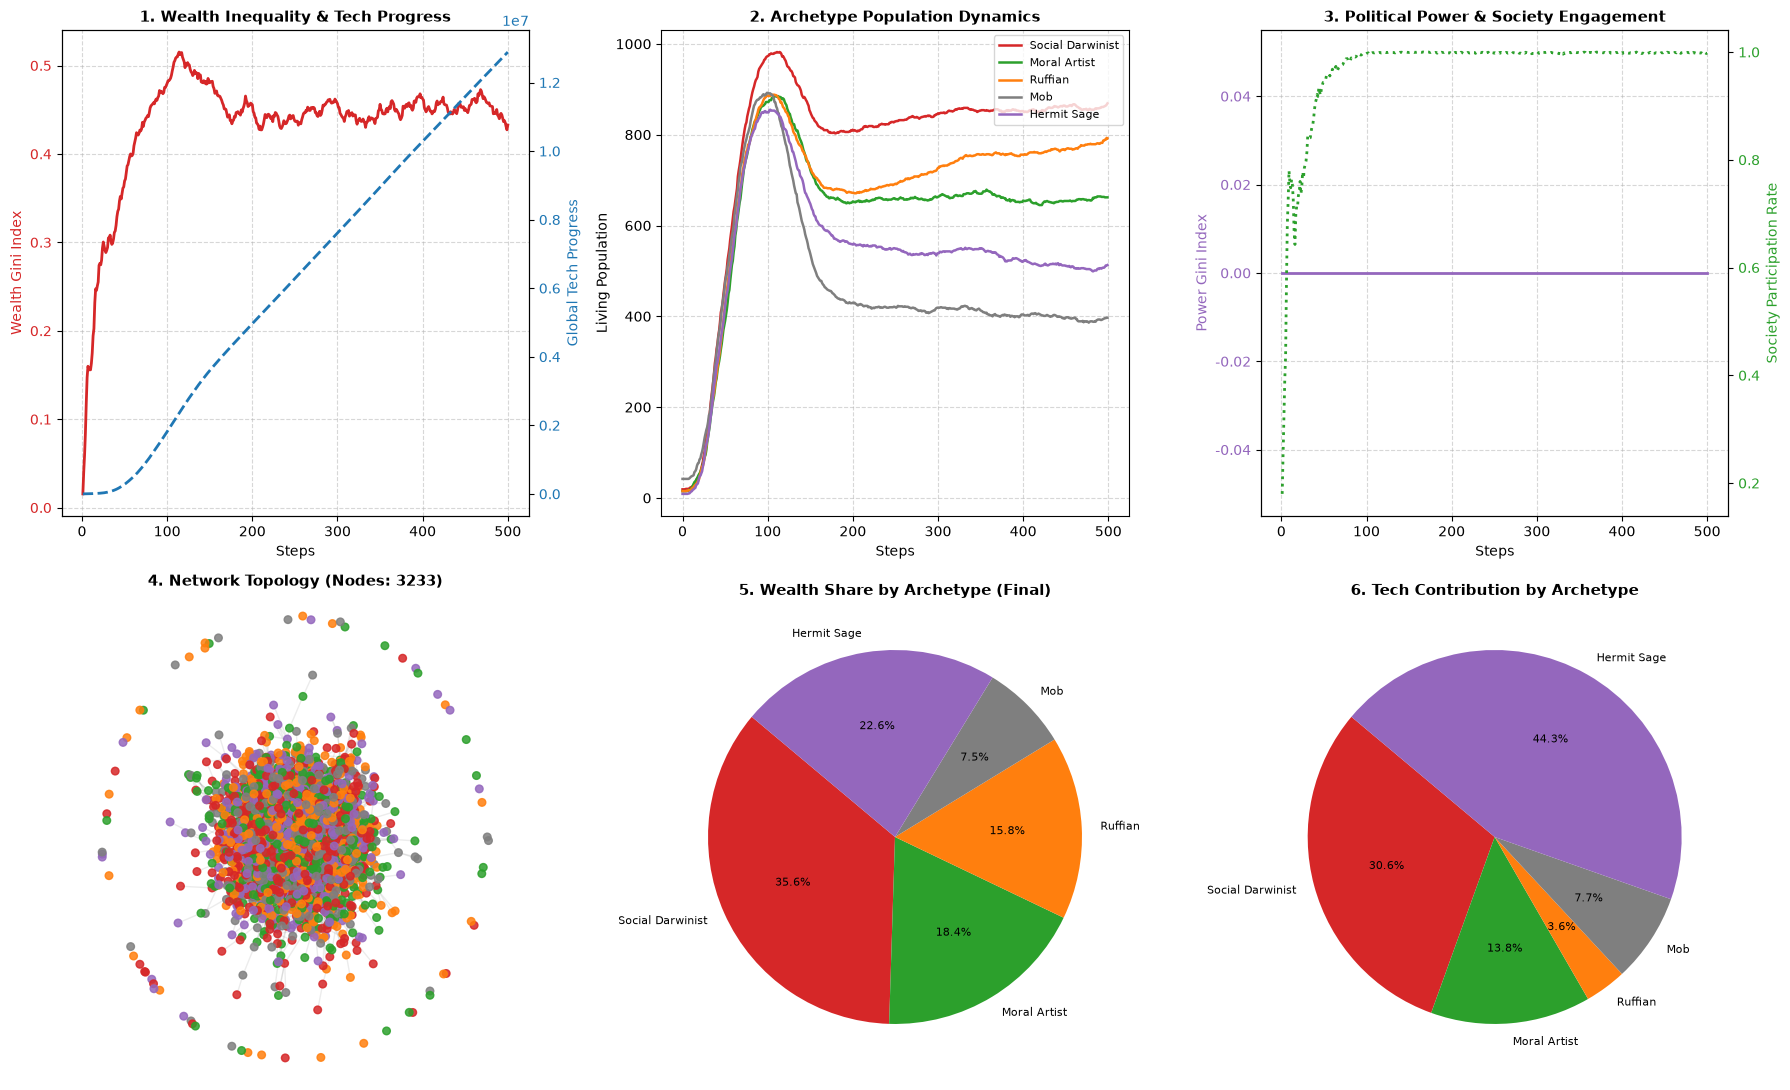

✅ Cell 9: 全景计算社会学仪表盘生成完毕！模型 Cell 1–9 全流程闭环无缝联动。 / Panoramic computational sociology dashboard generated successfully! Seamless end-to-end integration across Cells 1–9.


In [9]:
# Cell 9: 计算社会学全景数据分析仪表盘 (可视化模块 - 字体容错增强版) / Computational Sociology Panoramic Data Dashboard (Visualization Module - Font Fault-Tolerant Version)
# ==============================================================================

# 1. 字体与排版容错设置 (优先加载 Linux/Mac/Windows 常见中文字体，防止 Glyph 缺失警告) / Font & Layout settings
plt.rcParams['font.sans-serif'] = [
    'Noto Sans CJK SC', 'WenQuanYi Micro Hei', 'SimHei', 
    'Microsoft YaHei', 'DejaVu Sans', 'Arial', 'sans-serif'
]
plt.rcParams['axes.unicode_minus'] = False  # 正常显示负号 / Properly display minus sign

print("📊 正在生成计算社会学全景数据分析仪表盘... / Generating computational sociology panoramic dashboard...")

# 2. 创建 2x3 画布 / Create 2x3 subplot canvas
fig, axs = plt.subplots(2, 3, figsize=(18, 11))

steps_x = list(range(1, TOTAL_STEPS + 1))
data = model.datacollector.get_model_vars_dataframe() if hasattr(model, 'datacollector') else None

# 定义 5 个人格类型的标准色彩映射表 / Define standard color map for 5 archetypes
ARCHETYPE_COLORS = {
    'Social_Darwinist': '#d62728', # 达尔文主义者：红色 / Social Darwinist: Red
    'Moral_Artist': '#2ca02c',     # 道德艺术家：绿色 / Moral Artist: Green
    'Ruffian': '#ff7f0e',          # 暴徒/恶棍：橙色 / Ruffian: Orange
    'Mob': '#7f7f7f',              # 乌合之众/平民：灰色 / Mob: Gray
    'Hermit_Sage': '#9467bd'       # 隐士智者：紫色 / Hermit Sage: Purple
}

# ------------------------------------------------------------------------------
# 图 1: 财富基尼系数与全局科技演化 / Fig 1: Wealth Inequality & Tech Evolution
# ------------------------------------------------------------------------------
ax1 = axs[0, 0]
if data is not None and 'Gini' in data.columns:
    gini_series = data['Gini']
    tech_series = data['Tech_Progress']
else:
    gini_series = history_power_gini
    tech_series = [0] * TOTAL_STEPS

color_gini = '#d62728'
ax1.set_xlabel('Steps')
ax1.set_ylabel('Wealth Gini Index', color=color_gini)
ax1.plot(steps_x, gini_series, color=color_gini, linewidth=2, label='Wealth Gini')
ax1.tick_params(axis='y', labelcolor=color_gini)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1_sub = ax1.twinx()
color_tech = '#1f77b4'
ax1_sub.set_ylabel('Global Tech Progress', color=color_tech)
ax1_sub.plot(steps_x, tech_series, color=color_tech, linestyle='--', linewidth=2, label='Tech Progress')
ax1_sub.tick_params(axis='y', labelcolor=color_tech)
ax1.set_title("1. Wealth Inequality & Tech Progress", fontsize=11, fontweight='bold')

# ------------------------------------------------------------------------------
# 图 2: 五类人格种群数量演化 / Fig 2: Archetype Population Dynamics
# ------------------------------------------------------------------------------
ax2 = axs[0, 1]
if data is not None and 'Social_Darwinist_Count' in data.columns:
    for arch, col in ARCHETYPE_COLORS.items():
        col_name = f"{arch}_Count"
        if col_name in data.columns:
            ax2.plot(data.index, data[col_name], label=arch.replace('_', ' '), color=col, linewidth=1.8)
else:
    ax2.text(0.5, 0.5, "Population Data Unavailable", ha='center', va='center')

ax2.set_xlabel('Steps')
ax2.set_ylabel('Living Population')
ax2.set_title("2. Archetype Population Dynamics", fontsize=11, fontweight='bold')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.5)

# ------------------------------------------------------------------------------
# 图 3: 政治集中度与结社参与率 / Fig 3: Political Power & Society Engagement
# ------------------------------------------------------------------------------
ax3 = axs[0, 2]
color_p_gini = '#9467bd'
ax3.set_xlabel('Steps')
ax3.set_ylabel('Power Gini Index', color=color_p_gini)
ax3.plot(steps_x, history_power_gini, color=color_p_gini, linewidth=2, label='Power Gini')
ax3.tick_params(axis='y', labelcolor=color_p_gini)
ax3.grid(True, linestyle='--', alpha=0.5)

ax3_sub = ax3.twinx()
if data is not None and 'Society_Participation_Rate' in data.columns:
    part_rate = data['Society_Participation_Rate']
else:
    part_rate = history_top_leader_power

color_part = '#2ca02c'
ax3_sub.set_ylabel('Society Participation Rate', color=color_part)
ax3_sub.plot(steps_x, part_rate, color=color_part, linestyle=':', linewidth=2, label='Participation Rate')
ax3_sub.tick_params(axis='y', labelcolor=color_part)
ax3.set_title("3. Political Power & Society Engagement", fontsize=11, fontweight='bold')

# ------------------------------------------------------------------------------
# 图 4: 社交网络拓扑形态 / Fig 4: Social Network Topology
# ------------------------------------------------------------------------------
ax4 = axs[1, 0]
G = model.social_net.graph
if G.number_of_nodes() > 0:
    pos_net = nx.spring_layout(G, k=0.15, seed=42, iterations=30)
    
    # 根据存活 Agent 的人格动态映射节点颜色 / Dynamically map node colors based on alive agents' archetypes
    node_colors = []
    for node_id in G.nodes():
        agent = model.agents_dict.get(node_id)
        if agent and agent.is_alive:
            node_colors.append(ARCHETYPE_COLORS.get(agent.archetype, '#1f77b4'))
        else:
            node_colors.append('#d3d3d3') # 死亡节点呈浅灰 / Deceased nodes in light gray
            
    nx.draw_networkx_nodes(G, pos_net, ax=ax4, node_size=30, node_color=node_colors, alpha=0.85)
    nx.draw_networkx_edges(G, pos_net, ax=ax4, alpha=0.15, edge_color='gray')
    ax4.set_title(f"4. Network Topology (Nodes: {G.number_of_nodes()})", fontsize=11, fontweight='bold')
else:
    ax4.text(0.5, 0.5, "No Social Connections Formed", ha='center', va='center')
ax4.axis('off')

# ------------------------------------------------------------------------------
# 图 5: 终局各类人格财富份额 / Fig 5: Wealth Share by Archetype (Final)
# ------------------------------------------------------------------------------
ax5 = axs[1, 1]
final_metrics = model.collect_social_metrics()
wealth_share = final_metrics.get('arch_wealth_share', {})

# 过滤掉份额为 0 的项，防止绘图重叠 / Filter out zero shares to avoid plot overlap
valid_wealth = {k: v for k, v in wealth_share.items() if v > 0}
if valid_wealth:
    labels = [k.replace('_', ' ') for k in valid_wealth.keys()]
    sizes = list(valid_wealth.values())
    colors = [ARCHETYPE_COLORS.get(k, '#1f77b4') for k in valid_wealth.keys()]
    ax5.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, textprops={'fontsize': 8})
    ax5.set_title("5. Wealth Share by Archetype (Final)", fontsize=11, fontweight='bold')
else:
    ax5.text(0.5, 0.5, "No Wealth Data Available", ha='center', va='center')

# ------------------------------------------------------------------------------
# 图 6: 各人格类型累积科研贡献 / Fig 6: Tech Contribution Share by Archetype
# ------------------------------------------------------------------------------
ax6 = axs[1, 2]

tech_share = {}

# 途径 1: 尝试从 collect_social_metrics 中匹配可能存在的各种 key 命名 / Approach 1: Match potential keys from collect_social_metrics
for possible_key in ['tech_share', 'arch_tech_share', 'arch_tech_contrib', 'tech_contrib']:
    if possible_key in final_metrics and final_metrics[possible_key]:
        tech_share = final_metrics[possible_key]
        break

# 途径 2: 若途径 1 未拿到，直接从 model.research_stats 原生字典中提取贡献量 / Approach 2: Extract directly from model.research_stats
if not tech_share and hasattr(model, 'research_stats') and model.research_stats:
    tech_share = {
        arch: info.get('contrib', 0.0) if isinstance(info, dict) else info
        for arch, info in model.research_stats.items()
    }

# 途径 3: 若仍未拿到，从 DataCollector 最后一轮的历史数据中提取 / Approach 3: Extract from DataCollector last step
if not tech_share and data is not None and not data.empty:
    last_row = data.iloc[-1]
    for arch in ARCHETYPE_COLORS.keys():
        for col in [f"Tech_Contrib_{arch}", f"tech_contrib_{arch}"]:
            if col in last_row:
                tech_share[arch] = last_row[col]
                break

# 过滤掉贡献 <= 0 的项 / Filter out non-positive contributions
valid_tech = {k: float(v) for k, v in tech_share.items() if float(v) > 0}

if valid_tech:
    labels = [k.replace('_', ' ') for k in valid_tech.keys()]
    sizes = list(valid_tech.values())
    colors = [ARCHETYPE_COLORS.get(k, '#1f77b4') for k in valid_tech.keys()]
    ax6.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, textprops={'fontsize': 8})
    ax6.set_title("6. Tech Contribution by Archetype", fontsize=11, fontweight='bold')
else:
    ax6.text(0.5, 0.5, "No Tech Contribution Recorded\n(Zero Research Produced)", ha='center', va='center')

plt.tight_layout()
plt.show()

print("✅ Cell 9: 全景计算社会学仪表盘生成完毕！模型 Cell 1–9 全流程闭环无缝联动。 / Panoramic computational sociology dashboard generated successfully! Seamless end-to-end integration across Cells 1–9.")